## ADJUVANT dataset

This Jupyter Notebook conatains the code to generate results of Figure 4 in the article's main text.


In [1]:
import pandas as pd
import numpy as np
import sys, os

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.adjuvant_utils import *
from src.run_utils import survb_bounds_adjuvant, cox_model
from src.load_utils import *


### SurvB-learner estimation

In [2]:
data_path = f"{project_root}/data/adjuvant_data/multigene-171_combined.csv"

for time_indicator in ["OS"]:
    X, A, y, Delta, x_name = read_in_adjuvant(data_path, time_indicator)
    survb_est = survb_bounds_adjuvant(X, A, y, Delta, "non_informative", time_indicator)

    X_df = pd.DataFrame(X, columns=x_name)
    df = pd.concat([X_df, pd.DataFrame({'A': A, 'y': y, 'Delta': Delta})], axis=1)
    df['lb_A_0_est'] = survb_est[0]
    df['up_A_0_est'] = survb_est[1]
    df['lb_A_1_est'] = survb_est[2]
    df['up_A_1_est'] = survb_est[3]
    df['lb_cate_est'] = survb_est[4]
    df['up_cate_est'] = survb_est[5]

    A_0_est, A_1_est = cox_model(df)
    df['A_0_est'] = A_0_est
    df['A_1_est'] = A_1_est

    print(f"finished {time_indicator}")
    df.to_csv(f'{project_root}/results/adjuvant_data/{time_indicator.lower()}_with_est.csv', index=True)

finished OS


In [3]:
data_path = f"{project_root}/results/adjuvant_data"
df_dfs = pd.read_csv(f"{data_path}/dfs_with_est.csv")
df_os = pd.read_csv(f"{data_path}/os_with_est.csv")

## Main text Figure 4

**Findings for the ADJUVANT trial.** The ADJUVANT trial (Liu et al., Zhong et al.) assess the effect of adjuvant gefitinib in $N=171$ patients with EGFR-mutant stage II--IIIA non-small cell lung cancer (NSCLC), yet whether the original study was subject to large censoring (36.84 \% for DFS and 63.18\% for OS). Hence, our aim is to identify subgroups of patients that have a robust treatment benefit despite potential informative censoring. To do so, we report the proportion of patients where the lower bounds (LBs) of the CATE are strictly greater than zero (i.e., ``LBs > 0''), expressed as percentages (\%). So, a value close to 100\% indicates that nearly all patients in this subgroup benefit from treatment, with a CATE above zero despite potential informative censoring.

### (A) General statistics

**Table**

Patient characteristics: The table on the left characterizes the baseline characteristics and genetic alterations of the patient population.

In [3]:
sample_size_table(df_dfs)

Covariates     |  Sample sizes   
Baseline characteristics
-----------------------------------
Age            |  170            
  >=55         |  114            
  <55          |  56             
Sex            |  170            
  Male         |  71             
  Female       |  99             
Pathology      |  170            
  I            |  162            
  II           |  4              
  III          |  4              
Clinical Stage |  170            
  II           |  57             
  III          |  113            

Genes
-----------------------------------
CDK4           |  170            
  0            |  158            
  1            |  12             
MYC            |  170            
  0            |  155            
  1            |  15             
NKX2-1         |  170            
  0            |  137            
  1            |  33             
SMAD4          |  170            
  0            |  155            
  1            |  15             
TP53        

### (B) Single-covariate analysis

Single-covariate analysis: Forest plots show the mean and standard deviation of the estimated lower bounds of the CATE within subgroups defined by baseline characteristics or genetic covariates by bootstrap. For each subgroup on the x-axis, we performed $2000$ bootstrap replications. The background scatter points represent the CATE lower-bound estimates without bootstrapping, and the size of the mean point is proportional to the subgroup sample size. 

**forest** **plot**

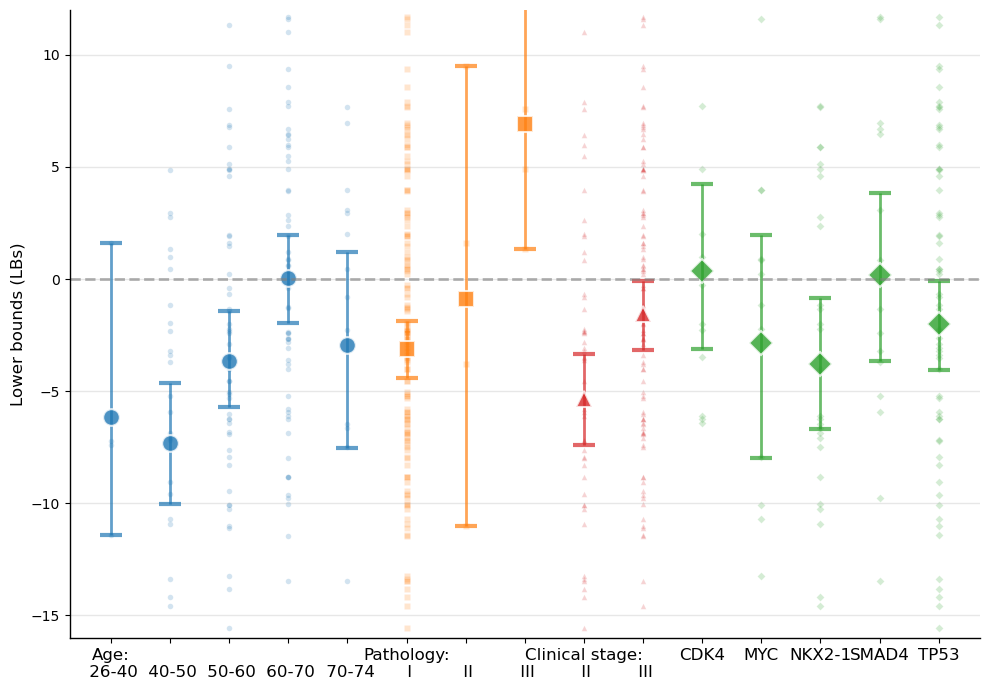

In [6]:
bootstrap_results = forest_plot_bootstrap(df_dfs, 'DFS', project_root, 'lb', n_bootstrap=2000)

**Table**

In [8]:
LBs_single_cov_table(df_dfs, 'DFS')

Subgroup            |  Sample size |  LBs > 0
Age 26-40           |  4           |  25.00%
Age 40-50           |  29          |  20.69%
Age 50-60           |  56          |  30.36%
Age 60-70           |  66          |  50.00%
Age 70-74           |  13          |  46.15%
Pathology I         |  162         |  35.80%
Pathology II        |  4           |  50.00%
Pathology III       |  4           |  100.00%
Clinical stage II   |  57          |  22.81%
Clinical stage III  |  113         |  45.13%
CDK4                |  12          |  41.67%
MYC                 |  15          |  46.67%
NKX2-1              |  33          |  30.30%
SMAD4               |  15          |  46.67%
TP53                |  72          |  44.44%


### (C) Data-driven analysis

Data-driven analysis: Using recursive partition, with a customized criterion that selects the subgroup with the highest percentage of LBs above zero, we computed a tree based on the lower-bound estimates that identifies the most informative covariates for stratifying the population into subgroups with different treatment effects. 

In [9]:
tree_info = build_custom_tree(df_dfs, "lb_cate_est", max_depth=2)

Custom Decision Tree (maximizing percentage of y>0):
MYC_Gain <= 0.0000
  LBs>0%=0.3765
  ├─ Left:
    TP53_alteration <= 0.0000
      LBs>0%=0.3677
      ├─ Left:
        Leaf: value=-3.6520, LBs>0%=0.3043
      └─ Right:
        Leaf: value=-1.6390, LBs>0%=0.4603
  └─ Right:
    CDK4 <= 0.0000
      LBs>0%=0.4667
      ├─ Left:
        Leaf: value=-4.0958, LBs>0%=0.4286
      └─ Right:
        Leaf: value=14.5415, LBs>0%=1.0000


### (D) Co-alteration analysis

Co-alteration analysis: The heatmap (left) reports the probabilities that the non-informative lower bounds are above zero (``LBs > 0'') for pairs of genetic biomarkers, while the table (right, sorted alphabetically) summarizes these probabilities for both disease-free survival (DFS) and overall survival (OS) for selected genetic co-alterations. Hence, our framework provides robust evidence of treatment benefit for certain subgroups, even for the efficacy outcome (OS), despite the original study not being able to confirm this and in the presence of informative censoring that could otherwise bias the results. 

**Heatmap** **plots**

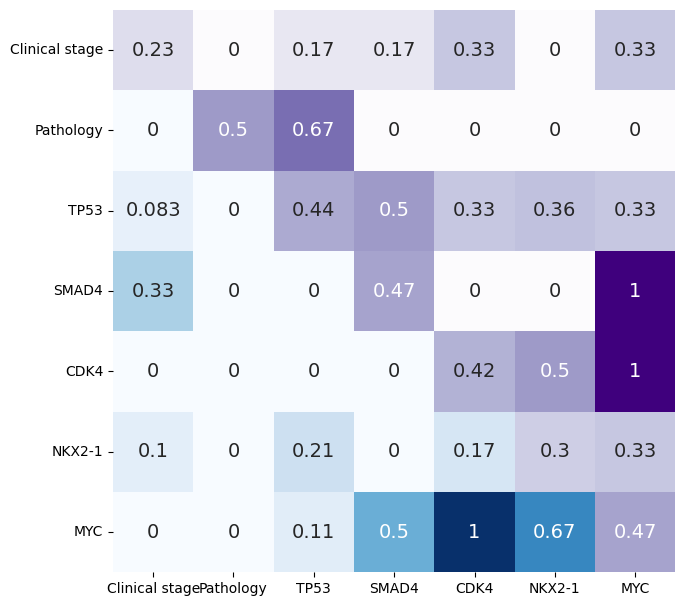

In [3]:
biomarkers = ['Clinical_stage', 'Pathology', 'TP53', 'SMAD4', 'CDK4', 'NKX2-1', 'MYC']
lb_mat_dfs, lb_mat_os = twoD_heatmap(df_dfs, df_os, biomarkers, project_root)

**Table**

In [4]:
print_co_alteration_table(df_dfs, df_os)

Lower bounds (LBs) > 0 [%]
Biomarker co-alteration  DFS       OS
--------------------------------------------------
CDK4 + MYC               100.00%   100.00%
CDK4 + NKX2-1            50.00%    16.67%
NKX2-1 + MYC             33.33%    66.67%
SMAD4 + MYC              100.00%   50.00%
TP53 + MYC               33.33%    11.11%
TP53 + NKX2-1            35.71%    21.43%
TP53 + SMAD4             50.00%    0.00%


## Supplementary

### Table 1

**Dropout rates.** Shown are the dropout rates for DFS and OS across both treatment arms (gefitinib and chemotherapy)  and across different baseline characteristics (age, sex, pathology, clinical stage) and genes (CDK4, MYC, NKX2-1, SMAD4, TP53).

In [2]:
# Execute the analysis
adjuvant_data = pd.read_csv(f"{project_root}/data/adjuvant_data/multigene-171_combined.csv")
results = generate_survival_analysis_table(adjuvant_data, project_root)


Survival Rates by Subgroup (1 - Event rates)
          Subgroup  Sample_size  Gefitinib_rate_dfs%  Chemo_rate_dfs%  Gefitinib_rate_os%  Chemo_rate_os%
          Age_>=55          114                35.00            35.19               63.33           66.67
           Age_<55           56                48.57            28.57               62.86           57.14
          Sex_Male           71                47.50            38.71               65.00           64.52
        Sex_Female           99                34.55            29.55               61.82           63.64
       Pathology_I          162                42.70            32.88               64.04           64.38
      Pathology_II            4                 0.00              NaN               50.00             NaN
     Pathology_III            4                 0.00            50.00               50.00           50.00
 Clinical_stage_II           57                54.84            38.46               70.97           69.23
C

### Figure 7

**Single-covariate analysis for OS.**
The forest plot (left) shows the mean and standard deviation of the estimated lower bounds of the CATE within subgroups defined by baseline characteristics or genetic covariates by bootstrap. For each subgroup on the x-axis, we performed $2000$ bootstrap replications. The background scatter points represent the CATE lower bound estimates without bootstrapping. The table (right) reports the probabilities that the non-informative lower bounds are above zero (``LBs > 0'').

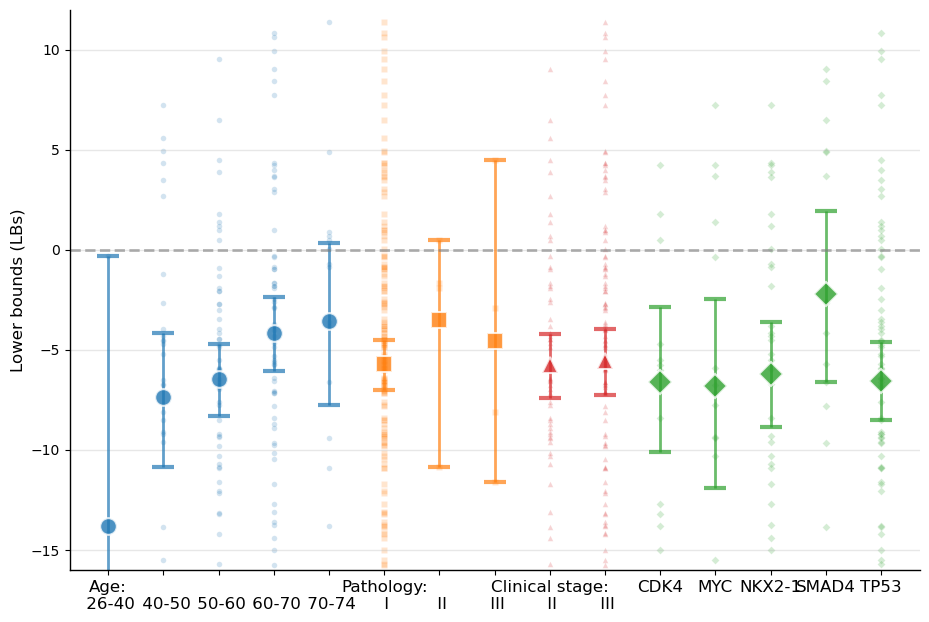

Subgroup            |  Sample size |  LBs > 0 (95% CI)
Age 26-40           |  4           |  0.00% (0.00%-48.99%)
Age 40-50           |  29          |  20.69% (9.85%-38.39%)
Age 50-60           |  56          |  16.07% (8.69%-27.81%)
Age 60-70           |  66          |  22.73% (14.29%-34.17%)
Age 70-74           |  13          |  46.15% (23.21%-70.86%)
Pathology I         |  162         |  20.99% (15.43%-27.89%)
Pathology II        |  4           |  25.00% (4.56%-69.94%)
Pathology III       |  4           |  25.00% (4.56%-69.94%)
Clinical stage II   |  57          |  17.54% (9.82%-29.37%)
Clinical stage III  |  113         |  23.01% (16.21%-31.58%)
CDK4                |  12          |  25.00% (8.89%-53.23%)
MYC                 |  15          |  26.67% (10.90%-51.95%)
NKX2-1              |  33          |  24.24% (12.83%-41.02%)
SMAD4               |  15          |  40.00% (19.82%-64.25%)
TP53                |  72          |  22.22% (14.17%-33.09%)


In [4]:
forest_plot_bootstrap(df_os, 'OS', project_root, n_bootstrap=2000)
LBs_single_cov_table(df_os, 'OS')

### Figure 8

**Data-driven analysis for OS.** Using a tailored recursive partition algorithm, we select subgroups with the highest percentage of LBs above zero. Method details are in Supplement F.

In [5]:
tree_info = build_custom_tree(df_os, "lb_cate_est", max_depth=2)

Custom Decision Tree (maximizing percentage of y>0):
SMAD4 <= 0.0000
  n=170, LBs>0%=21.18% (15.71%-27.92%)
  ├─ Left:
    CDK4 <= 0.0000
      n=155, LBs>0%=19.35% (13.91%-26.28%)
      ├─ Left:
        Leaf: value=-5.8987, n=143, LBs>0%=18.88% (13.31%-26.08%)
      └─ Right:
        Leaf: value=-6.5501, n=12, LBs>0%=25.00% (8.89%-53.23%)
  └─ Right:
    MYC_Gain <= 0.0000
      n=15, LBs>0%=40.00% (19.82%-64.25%)
      ├─ Left:
        Leaf: value=-1.4867, n=13, LBs>0%=38.46% (17.71%-64.48%)
      └─ Right:
        Leaf: value=-6.7465, n=2, LBs>0%=50.00% (9.45%-90.55%)
